# Lesson 10 - Stress tests and the final report

A model that works on one test set may fail in the real world. The presentation promised four stress tests,
plus one experiment showing why fair splits matter:

| experiment | question | run |
|---|---|---|
| E5 leaky split | how much does letting the same ship into train and test inflate accuracy? | `--split-mode leaky` |
| E6 distance | does recognition fail for far ships? | from the normal evaluation |
| E7 hydrophone shift | does a model trained on one microphone work on another? | `--hydrophone-shift` |
| E8 noise | how does it degrade in noisier water, and does it say "unknown"? | `evaluate.py --noise 20 10 0` |

At the end, this notebook gathers the key numbers and figures into `runs/report/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import shutil
import matplotlib.pyplot as plt
import pandas as pd
from paths import RUNS_DIR

def metrics(run_name):
    p = RUNS_DIR / run_name / "eval" / "metrics.json"
    return json.loads(p.read_text()) if p.exists() else None

def missing(run_name, train_cmd, eval_extra=""):
    print(f"no evaluated run '{run_name}' yet:\n  python src/train.py {train_cmd}\n"
          f"  python src/evaluate.py runs/{run_name}{eval_extra}")

E2, E5, E7 = "class_f1_efficientnet_b0_vessel", "class_f1_efficientnet_b0_leaky", "class_f1_efficientnet_b0_vessel_hyd"
base = metrics(E2)
if base is None:
    missing(E2, "--task class", " --mc 20")

## E5 - The leaky split

The leaky split has the same number of clips per split, but shuffled without regard to which ship they come from,
so test ships were also heard in training. The gap between the two accuracies is the **inflation** that earlier
benchmarks suffered from (the paper reports 10-48 points).

In [2]:
leaky = metrics(E5)
if leaky is None:
    missing(E5, "--task class --split-mode leaky")
elif base:
    gap = pd.DataFrame({"vessel-disjoint (fair)": base["closed_set"], "leaky": leaky["closed_set"]}).loc[["accuracy", "macro_f1"]]
    display(gap.astype(float).round(3))
    print(f"inflation: {100 * (leaky['closed_set']['accuracy'] - base['closed_set']['accuracy']):.1f} accuracy points")

,vessel-disjoint (fair),leaky
accuracy,0.324,0.858
macro_f1,0.290,0.857


inflation: 53.3 accuracy points


## E6 - Accuracy by distance

,n,accuracy
near <700 m,770.0,0.433766
mid 700-1400 m,1532.0,0.325718
far >1400 m,1804.0,0.217295


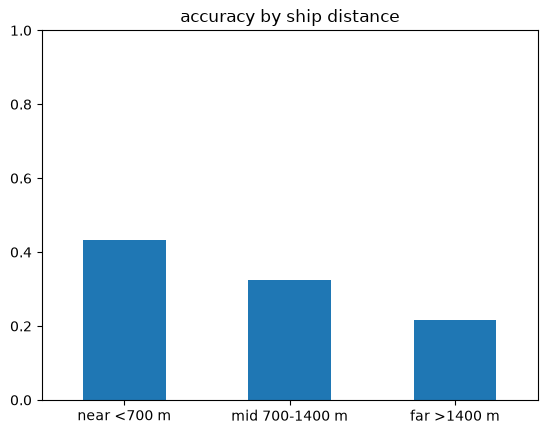

In [3]:
if base:
    d = pd.DataFrame(base["by_distance"]).T
    display(d)
    d["accuracy"].astype(float).plot.bar(rot=0, ylim=(0, 1), title="accuracy by ship distance"); plt.show()

## E7 - A different hydrophone

Trained on hydrophone ICLISTENAF2523 only, tested on ICLISTENAF2556 only. For a **fair** comparison, look at
the E2 model on the *same* 2556 test clips: E2 also heard 2556 during training. If E7 is clearly worse there,
the model partly learned the *microphone or location* instead of the ships. (E7 also trains on fewer clips,
which explains part of any drop.)

In [4]:
import data as D
from labels import CLASSES
from paths import DATA_DIR

hyd = metrics(E7)
if hyd is None:
    missing(E7, "--task class --hydrophone-shift")
elif base:
    _, table = D.open_features(DATA_DIR)
    def acc_on_2556(run_name):
        p = pd.read_parquet(RUNS_DIR / run_name / "eval" / "predictions.parquet")
        p = p[(p.y_class >= 0) & (table.hydrophone.iloc[p.row].fillna("").to_numpy() == "ICLISTENAF2556")]
        return float((p.pred_class == p.label).mean()), len(p)
    (a2, n2), (a7, n7) = acc_on_2556(E2), acc_on_2556(E7)
    display(pd.DataFrame({"E2 (heard both hydrophones)": {"accuracy on 2556 ship clips": a2, "clips": n2},
                          "E7 (heard only 2523)": {"accuracy on 2556 ship clips": a7, "clips": n7}}).round(3))

,E2 (heard both hydrophones),E7 (heard only 2523)
accuracy on 2556 ship clips,0.326,0.259
clips,905.000,905.000


## E8 - Added noise

White noise is mixed into the raw audio at decreasing signal-to-noise ratios (20 dB = mild, 0 dB = noise as
loud as the recording). Ideally accuracy degrades slowly and the model flags more clips as "unknown" as it gets
less sure. (Needs the audio zip on this machine.)

,accuracy,flagged_unknown,n
clean,0.346,0.054,1000.0
20.0 dB,0.225,0.035,1000.0
10.0 dB,0.158,0.029,1000.0
0.0 dB,0.130,0.008,1000.0


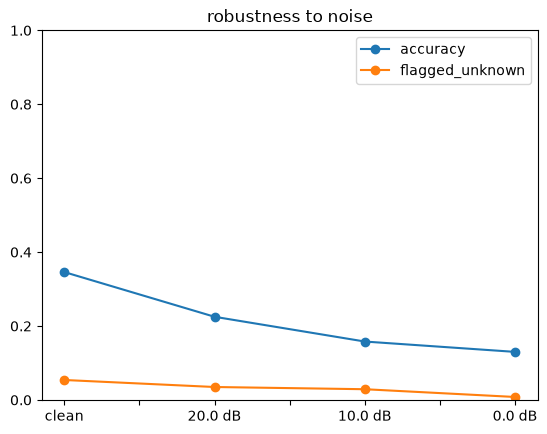

In [5]:
if base and "noise" in base:
    n = pd.DataFrame(base["noise"]).T
    display(n)
    n[["accuracy", "flagged_unknown"]].astype(float).plot(marker="o", ylim=(0, 1), title="robustness to noise"); plt.show()
elif base:
    print(f"no noise results:  python src/evaluate.py runs/{E2} --mc 20 --noise 20 10 0")

## The report: one table, key figures

Collect the headline number of every evaluated run, and copy the main figures to `runs/report/`.

In [6]:
rows = []
for m_path in sorted(RUNS_DIR.glob("*/eval/metrics.json")):
    m = json.loads(m_path.read_text())
    row = {"run": m["run"], "task": m["task"]}
    if "closed_set" in m:
        row.update(accuracy=m["closed_set"]["accuracy"], macro_f1=m["closed_set"]["macro_f1"],
                   ece_after_T=m["calibration"]["ece_after"])
    if "open_set" in m:
        row.update(auroc_msp=m["open_set"]["msp"]["auroc"], auroc_energy=m["open_set"]["energy"]["auroc"])
    for t, r in m.get("regression", {}).items():
        row[f"{t}_MAE"] = r["mae"]; row[f"{t}_baseline_MAE"] = r["baseline_mae"]
    rows.append(row)
baseline = RUNS_DIR / "baseline_f1" / "metrics.json"
if baseline.exists():
    b = json.loads(baseline.read_text())
    rows.append({"run": "baseline_f1 (classical)", "task": "class+distance+speed", "accuracy": b["class"]["accuracy"],
                 "macro_f1": b["class"]["macro_f1"], "distance_MAE": b["distance"]["mae"], "speed_MAE": b["speed"]["mae"]})
if not rows:
    print("nothing evaluated yet - follow README section 4")
else:
    report = RUNS_DIR / "report"
    report.mkdir(exist_ok=True)
    summary = pd.DataFrame(rows).round(3)
    summary.to_csv(report / "summary.csv", index=False)
    display(summary)
    for m_path in RUNS_DIR.glob("*/eval/*.png"):
        shutil.copy(m_path, report / f"{m_path.parent.parent.name}__{m_path.name}")
    print(f"saved {report / 'summary.csv'} and {len(list(report.glob('*.png')))} figures in {report}")

,run,task,accuracy,macro_f1,ece_after_T,auroc_msp,auroc_energy,distance_MAE,distance_baseline_MAE,speed_MAE,speed_baseline_MAE
0,class_f1_efficientnet_b0_leaky,class,0.858,0.857,0.016,NaN,NaN,NaN,NaN,NaN,NaN
1,class_f1_efficientnet_b0_vessel,class,0.324,0.290,0.093,NaN,NaN,NaN,NaN,NaN,NaN
2,class_f1_efficientnet_b0_vessel_hA,class,0.448,0.377,0.084,0.500,0.525,NaN,NaN,NaN,NaN
3,class_f1_efficientnet_b0_vessel_hB,class,0.444,0.385,0.043,0.579,0.579,NaN,NaN,NaN,NaN
4,class_f1_efficientnet_b0_vessel_hC,class,0.421,0.363,0.115,0.508,0.569,NaN,NaN,NaN,NaN
5,class_f1_efficientnet_b0_vessel_hyd,class,0.402,0.304,0.068,NaN,NaN,NaN,NaN,NaN,NaN
6,class_f1_efficientnet_b0_vessel_merged,class,0.367,0.370,0.107,NaN,NaN,NaN,NaN,NaN,NaN
7,distance_f1_efficientnet_b0_vessel,distance,NaN,NaN,NaN,NaN,NaN,275.379,403.006,NaN,NaN
8,speed_f1_efficientnet_b0_vessel,speed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.938,3.64
9,baseline_f1 (classical),class+distance+speed,0.318,0.277,NaN,NaN,NaN,273.799,NaN,2.955,NaN


saved D:\shipsound\runs\report\summary.csv and 27 figures in D:\shipsound\runs\report


## Writing it up

A good results section answers the presentation's four questions with these numbers:

1. **Recognise known ship types** on unseen ships: E2 accuracy and macro-F1 vs the classical baseline (E1),
   with the rare-class warning for pilot vessel and dredger.
2. **Flag unknown ships better than softmax**: lesson 07's AUROC table, MSP vs energy vs MC dropout averaged over
   groups A, B, C, and the deep ensemble on group A.
3. **Make confidence trustworthy**: ECE before/after temperature scaling (lesson 08).
4. **Show how leaky splits inflate accuracy**: E5.

Plus distance and speed (lesson 09) and the stress tests (E6-E8). Always report the fold, and say clearly
what the model was **not** tested on: other locations, multiple ships at once, ships beyond 2 km.